# Real-world Data Wrangling

In this project, you will apply the skills you acquired in the course to gather and wrangle real-world data with two datasets of your choice.

You will retrieve and extract the data, assess the data programmatically and visually, accross elements of data quality and structure, and implement a cleaning strategy for the data. You will then store the updated data into your selected database/data store, combine the data, and answer a research question with the datasets.

Throughout the process, you are expected to:

1. Explain your decisions towards methods used for gathering, assessing, cleaning, storing, and answering the research question
2. Write code comments so your code is more readable

## 1. Gather data

In this section, you will extract data using two different data gathering methods and combine the data. Use at least two different types of data-gathering methods.

### **1.1.** Problem Statement
In 2-4 sentences, explain the kind of problem you want to look at and the datasets you will be wrangling for this project.

I want to investigate how state-level demographic and economic characteristics relate to firearm background check activity across the United States. Specifically, I aim to determine which factors — such as population size, median household income, education level, and veteran status — are most strongly associated with per-capita firearm background check rates. To explore this, I will wrangle two datasets: (1) FBI NICS firearm background check data, which contains monthly state-level records of background checks by firearm type, and (2) US Census demographic data, which provides population, income, education, and other socioeconomic indicators for each state.

### **1.2.** Gather at least two datasets using two different data gathering methods

List of data gathering methods:

- Download data manually
- Programmatically downloading files
- Gather data by accessing APIs
- Gather and extract data from HTML files using BeautifulSoup
- Extract data from a SQL database

Each dataset must have at least two variables, and have greater than 500 data samples within each dataset.

For each dataset, briefly describe why you picked the dataset and the gathering method (2-3 full sentences), including the names and significance of the variables in the dataset. Show your work (e.g., if using an API to download the data, please include a snippet of your code).

Load the dataset programmtically into this notebook.

#### **Dataset 1**

Type: CSV File

Method: The data was gathered using the **"Downloading files manually"** method from the FBI's National Instant Criminal Background Check System (NICS). The CSV file was downloaded directly from the FBI NICS website and saved locally. This dataset is valuable because it provides granular, monthly state-level data on firearm background checks across multiple categories.

Dataset variables:

*   **month**: The year-month of the background check record (e.g., "2017-09")
*   **state**: The US state where the background check was conducted
*   **permit**: Number of permit-related background checks
*   **handgun**: Number of background checks for handgun purchases
*   **long_gun**: Number of background checks for long gun (rifle/shotgun) purchases
*   **totals**: Total number of background checks for that state-month combination

In [1]:
# Import necessary libraries for the entire project
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import warnings

# Suppress warnings for cleaner output
warnings.filterwarnings('ignore')

# Set plot style for consistent, professional visualizations
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

# Helper function for formatting plots consistently
def format_plot(ax, title, xlabel, ylabel):
    """Apply consistent formatting to matplotlib axes."""
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(axis='both', labelsize=10)
    return ax

In [2]:
# METHOD 1: Manual Download - Load FBI NICS firearm background check data
# The CSV was manually downloaded from the FBI NICS website
gun_data = pd.read_csv('gun_data.csv')

# Display basic info about the dataset
print(f"Dataset shape: {gun_data.shape}")
print(f"Number of rows (samples): {gun_data.shape[0]}")
print(f"Number of columns (variables): {gun_data.shape[1]}")
print(f"\nColumn names:\n{list(gun_data.columns)}")
print(f"\nFirst 5 rows:")
gun_data.head()

Dataset shape: (12485, 27)
Number of rows (samples): 12485
Number of columns (variables): 27

Column names:
['month', 'state', 'permit', 'permit_recheck', 'handgun', 'long_gun', 'other', 'multiple', 'admin', 'prepawn_handgun', 'prepawn_long_gun', 'prepawn_other', 'redemption_handgun', 'redemption_long_gun', 'redemption_other', 'returned_handgun', 'returned_long_gun', 'returned_other', 'rentals_handgun', 'rentals_long_gun', 'private_sale_handgun', 'private_sale_long_gun', 'private_sale_other', 'return_to_seller_handgun', 'return_to_seller_long_gun', 'return_to_seller_other', 'totals']

First 5 rows:


,month,state,permit,permit_recheck,handgun,long_gun,other,multiple,admin,prepawn_handgun,...,returned_other,rentals_handgun,rentals_long_gun,private_sale_handgun,private_sale_long_gun,private_sale_other,return_to_seller_handgun,return_to_seller_long_gun,return_to_seller_other,totals
0,2017-09,Alabama,16717.0,0.0,5734.0,6320.0,221.0,317,0.0,15.0,...,0.0,0.0,0.0,9.0,16.0,3.0,0.0,0.0,3.0,32019
1,2017-09,Alaska,209.0,2.0,2320.0,2930.0,219.0,160,0.0,5.0,...,0.0,0.0,0.0,17.0,24.0,1.0,0.0,0.0,0.0,6303
2,2017-09,Arizona,5069.0,382.0,11063.0,7946.0,920.0,631,0.0,13.0,...,0.0,0.0,0.0,38.0,12.0,2.0,0.0,0.0,0.0,28394
3,2017-09,Arkansas,2935.0,632.0,4347.0,6063.0,165.0,366,51.0,12.0,...,0.0,0.0,0.0,13.0,23.0,0.0,0.0,2.0,1.0,17747
4,2017-09,California,57839.0,0.0,37165.0,24581.0,2984.0,0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,123506


#### Dataset 2

Type: CSV File loaded into a SQLite database

Method: The data was gathered using the **"Extract data from a SQL database"** method. The US Census demographic data was first loaded into a local SQLite database, then queried using SQL via Python's `sqlite3` module. This approach demonstrates a different gathering method and is useful for larger datasets where SQL queries can filter and aggregate data efficiently.

Dataset variables:

*   **Fact**: The name of the demographic or economic measure (e.g., "Population estimates", "Median household income")
*   **State columns (Alabama through Wyoming)**: The value of each fact for each US state — this wide format will need restructuring later
*   **Key facts include**: Population estimates, Median household income, Bachelor's degree or higher percentage, Veterans count, Population per square mile

In [3]:
# METHOD 2: SQL Database - Load US Census data into SQLite, then query with SQL

# Step 1: Load the raw CSV into a SQLite database
census_raw = pd.read_csv('us_census_data.csv')

# Create a SQLite database and store the census data
conn = sqlite3.connect('census_data.db')
census_raw.to_sql('census', conn, if_exists='replace', index=False)

# Step 2: Query the data back from the database using SQL
# This demonstrates the SQL gathering method
query = "SELECT * FROM census"
census_data = pd.read_sql_query(query, conn)

# Close the connection (we'll reopen later if needed)
conn.close()

# Display basic info about the dataset
print(f"Dataset shape: {census_data.shape}")
print(f"Number of rows (facts): {census_data.shape[0]}")
print(f"Number of columns (states + metadata): {census_data.shape[1]}")
print(f"\nColumn names (first 10):\n{list(census_data.columns[:10])}")
print(f"\nFact names (first 15):")
for i, fact in enumerate(census_data['Fact'].head(15)):
    print(f"  {i+1}. {fact}")
print(f"\nFirst 5 rows (subset of columns):")
census_data[['Fact', 'Alabama', 'Alaska', 'California']].head()

Dataset shape: (85, 52)
Number of rows (facts): 85
Number of columns (states + metadata): 52

Column names (first 10):
['Fact', 'Fact Note', 'Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware']

Fact names (first 15):
  1. Population estimates, July 1, 2016,  (V2016)
  2. Population estimates base, April 1, 2010,  (V2016)
  3. Population, percent change - April 1, 2010 (estimates base) to July 1, 2016,  (V2016)
  4. Population, Census, April 1, 2010
  5. Persons under 5 years, percent, July 1, 2016,  (V2016)
  6. Persons under 5 years, percent, April 1, 2010
  7. Persons under 18 years, percent, July 1, 2016,  (V2016)
  8. Persons under 18 years, percent, April 1, 2010
  9. Persons 65 years and over, percent,  July 1, 2016,  (V2016)
  10. Persons 65 years and over, percent, April 1, 2010
  11. Female persons, percent,  July 1, 2016,  (V2016)
  12. Female persons, percent, April 1, 2010
  13. White alone, percent, July 1, 2016,  (V2016)
  14. 

,Fact,Alabama,Alaska,California
0,"Population estimates, July 1, 2016, (V2016)","4,863,300","741,894","39,250,017"
1,"Population estimates base, April 1, 2010, (V2...","4,780,131","710,249","37,254,522"
2,"Population, percent change - April 1, 2010 (es...",1.70%,4.50%,5.40%
3,"Population, Census, April 1, 2010","4,779,736","710,231","37,253,956"
4,"Persons under 5 years, percent, July 1, 2016, ...",6.00%,7.30%,6.30%


Optional data storing step: You may save your raw dataset files to the local data store before moving to the next step.

In [4]:
# Save raw datasets to preserve original data before any modifications
gun_data.to_csv('raw_gun_data.csv', index=False)
census_data.to_csv('raw_census_data.csv', index=False)
print("Raw datasets saved:")
print("  - raw_gun_data.csv")
print("  - raw_census_data.csv")

Raw datasets saved:
  - raw_gun_data.csv
  - raw_census_data.csv


## 2. Assess data

Assess the data according to data quality and tidiness metrics using the report below.

List **two** data quality issues and **two** tidiness issues. Assess each data issue visually **and** programmatically, then briefly describe the issue you find.  **Make sure you include justifications for the methods you use for the assessment.**

### Quality Issue 1:

In [5]:
# VISUAL ASSESSMENT: Display a sample of gun_data to visually inspect for missing values
# We look at columns that might have NaN values shown as blank cells
print("Visual inspection of gun_data - note the NaN values in many columns:")
gun_data.sample(10, random_state=42)

Visual inspection of gun_data - note the NaN values in many columns:


,month,state,permit,permit_recheck,handgun,long_gun,other,multiple,admin,prepawn_handgun,...,returned_other,rentals_handgun,rentals_long_gun,private_sale_handgun,private_sale_long_gun,private_sale_other,return_to_seller_handgun,return_to_seller_long_gun,return_to_seller_other,totals
2882,2013-05,Maryland,1.0,NaN,8507.0,5470.0,146.0,29,0.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14340
6962,2007-03,New Jersey,0.0,NaN,1652.0,1666.0,NaN,49,4.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3371
2865,2013-05,Colorado,8990.0,NaN,15666.0,12799.0,654.0,1057,8.0,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39181
4077,2011-07,Delaware,0.0,NaN,737.0,561.0,18.0,31,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1348
2798,2013-07,Vermont,0.0,NaN,862.0,967.0,44.0,42,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1915
3014,2013-03,South Dakota,7.0,NaN,3537.0,5315.0,94.0,212,0.0,0.0,...,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9506
12411,1998-12,North Dakota,0.0,NaN,403.0,1958.0,NaN,18,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2379
9414,2003-06,Florida,0.0,NaN,10197.0,8621.0,NaN,400,1.0,20.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20222
5961,2008-09,Mariana Islands,0.0,NaN,0.0,0.0,NaN,0,0.0,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
9266,2003-09,Mississippi,0.0,NaN,2567.0,6019.0,NaN,171,0.0,43.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11430


In [6]:
# PROGRAMMATIC ASSESSMENT: Count missing values per column
# We use isnull().sum() to quantify the extent of missing data
missing_counts = gun_data.isnull().sum()
missing_pct = (gun_data.isnull().sum() / len(gun_data) * 100).round(1)
missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing %': missing_pct
}).sort_values('Missing %', ascending=False)

print("Missing values in gun_data:")
print(missing_df[missing_df['Missing Count'] > 0])
print(f"\nTotal rows: {len(gun_data)}")
print(f"Columns with >50% missing: {(missing_pct > 50).sum()}")

Missing values in gun_data:
                           Missing Count  Missing %
rentals_long_gun                   11660       93.4
rentals_handgun                    11495       92.1
permit_recheck                     11385       91.2
returned_other                     10670       85.5
returned_long_gun                  10340       82.8
returned_handgun                   10285       82.4
return_to_seller_other             10230       81.9
return_to_seller_handgun           10010       80.2
private_sale_other                  9735       78.0
return_to_seller_long_gun           9735       78.0
private_sale_long_gun               9735       78.0
private_sale_handgun                9735       78.0
redemption_other                    7370       59.0
prepawn_other                       7370       59.0
other                               6985       55.9
prepawn_long_gun                    1945       15.6
prepawn_handgun                     1943       15.6
redemption_handgun                  

Issue and justification: **Extensive missing values in gun_data.** Many columns have significant amounts of missing data. Columns like `permit_recheck`, `prepawn_handgun`, `prepawn_long_gun`, `prepawn_other`, `returned_handgun`, `returned_long_gun`, `returned_other`, `rentals_handgun`, `rentals_long_gun`, `private_sale_handgun`, `private_sale_long_gun`, `private_sale_other`, `return_to_seller_handgun`, `return_to_seller_long_gun`, and `return_to_seller_other` have very high percentages of missing values. This is a data quality issue because missing values can distort statistical analyses and lead to biased conclusions. I used `isnull().sum()` because it gives an exact count, and the visual inspection confirms blanks in the displayed table.

### Quality Issue 2:

In [7]:
# VISUAL ASSESSMENT: Display census data to visually inspect data types and formatting
# Look for inconsistent formatting: commas in numbers, percentage signs, etc.
print("Visual inspection of census_data - note commas in numbers and % signs:")
census_data[['Fact', 'Alabama', 'California', 'Texas']].head(10)

Visual inspection of census_data - note commas in numbers and % signs:


,Fact,Alabama,California,Texas
0,"Population estimates, July 1, 2016, (V2016)","4,863,300","39,250,017","27,862,596"
1,"Population estimates base, April 1, 2010, (V2...","4,780,131","37,254,522","25,146,100"
2,"Population, percent change - April 1, 2010 (es...",1.70%,5.40%,10.80%
3,"Population, Census, April 1, 2010","4,779,736","37,253,956","25,145,561"
4,"Persons under 5 years, percent, July 1, 2016, ...",6.00%,6.30%,7.20%
5,"Persons under 5 years, percent, April 1, 2010",6.40%,6.80%,7.70%
6,"Persons under 18 years, percent, July 1, 2016,...",22.60%,23.20%,26.20%
7,"Persons under 18 years, percent, April 1, 2010",23.70%,25.00%,27.30%
8,"Persons 65 years and over, percent, July 1, 2...",16.10%,13.60%,12.00%
9,"Persons 65 years and over, percent, April 1, 2010",13.80%,11.40%,10.30%


In [8]:
# PROGRAMMATIC ASSESSMENT: Check data types and identify formatting inconsistencies
# All state columns should be numeric but are stored as strings due to commas and %
print("Data types of selected state columns:")
print(census_data[['Alabama', 'California', 'Texas']].dtypes)
print()

# Show examples of problematic values
print("Examples of inconsistent data types:")
for idx in [0, 2, 25, 47, 48]:
    if idx < len(census_data):
        fact = census_data.iloc[idx]['Fact']
        val = census_data.iloc[idx]['Alabama']
        print(f"  Row {idx} ({fact[:50]}...): '{val}' (type: {type(val).__name__})")

Data types of selected state columns:
Alabama       str
California    str
Texas         str
dtype: object

Examples of inconsistent data types:
  Row 0 (Population estimates, July 1, 2016,  (V2016)...): '4,863,300' (type: str)
  Row 2 (Population, percent change - April 1, 2010 (estima...): '1.70%' (type: str)
  Row 25 (Median value of owner-occupied housing units, 2011...): '$125,500 ' (type: str)
  Row 47 (Median household income (in 2015 dollars), 2011-20...): '$43,623 ' (type: str)
  Row 48 (Per capita income in past 12 months (in 2015 dolla...): '$24,091 ' (type: str)


Issue and justification: **Census data has inconsistent data types.** The state columns in the census dataset contain values stored as strings with mixed formatting: population numbers include commas (e.g., "4,863,300"), percentages are stored as strings with percent signs (e.g., "1.70%"), and some values may contain footnote markers or special characters. This is a quality issue because these values cannot be used for numerical computations without cleaning. I verified this programmatically by checking the dtypes (all `object` instead of `float64`) and by printing sample values showing the mixed formatting patterns.

### Tidiness Issue 1:

In [9]:
# VISUAL ASSESSMENT: Display census data structure to show wide format
# Notice that states are columns instead of rows — violates tidy data principles
print("Census data structure — states are COLUMNS (wide format):")
print(f"Shape: {census_data.shape}")
print(f"\nColumns represent states: {list(census_data.columns[2:7])} ...")
print(f"Rows represent facts: {census_data['Fact'].iloc[0][:50]}...")
census_data.head(3)

Census data structure — states are COLUMNS (wide format):
Shape: (85, 52)

Columns represent states: ['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California'] ...
Rows represent facts: Population estimates, July 1, 2016,  (V2016)...


,Fact,Fact Note,Alabama,Alaska,Arizona,Arkansas,California,Colorado,Connecticut,Delaware,...,South Dakota,Tennessee,Texas,Utah,Vermont,Virginia,Washington,West Virginia,Wisconsin,Wyoming
0,"Population estimates, July 1, 2016, (V2016)",NaN,"4,863,300","741,894","6,931,071","2,988,248","39,250,017","5,540,545","3,576,452","952,065",...,865454,6651194,"27,862,596","3,051,217","624,594","8,411,808","7,288,000","1,831,102","5,778,708","585,501"
1,"Population estimates base, April 1, 2010, (V2...",NaN,"4,780,131","710,249","6,392,301","2,916,025","37,254,522","5,029,324","3,574,114","897,936",...,814195,6346298,"25,146,100","2,763,888","625,741","8,001,041","6,724,545","1,853,011","5,687,289","563,767"
2,"Population, percent change - April 1, 2010 (es...",NaN,1.70%,4.50%,8.40%,2.50%,5.40%,10.20%,0.10%,6.00%,...,0.063,0.048,10.80%,10.40%,-0.20%,5.10%,8.40%,-1.20%,1.60%,3.90%


In [10]:
# PROGRAMMATIC ASSESSMENT: Verify that state names are in columns instead of rows
# In tidy data, each variable should be a column and each observation a row
# Here, "state" is a variable but it's spread across 51 columns
state_columns = [c for c in census_data.columns if c not in ['Fact', 'Fact Note']]
print(f"Number of state columns: {len(state_columns)}")
print(f"State columns: {state_columns[:10]} ... (and {len(state_columns)-10} more)")
print(f"\nThis violates the tidy data rule: 'Each observation forms a row'")
print(f"Currently: {census_data.shape[0]} rows x {len(state_columns)} state columns")
print(f"Should be: ~{census_data.shape[0] * len(state_columns)} rows x 3 columns (Fact, State, Value)")

Number of state columns: 50
State columns: ['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'Florida', 'Georgia'] ... (and 40 more)

This violates the tidy data rule: 'Each observation forms a row'
Currently: 85 rows x 50 state columns
Should be: ~4250 rows x 3 columns (Fact, State, Value)


Issue and justification: **Census data is in wide format — states are columns instead of rows.** This violates the tidy data principle that "each observation should form a row." Currently, the census data has each state as a separate column, with facts as rows. In tidy format, there should be a single "State" column and a single "Value" column, with each row representing one fact-state observation. I confirmed this by checking that there are 51 state columns (50 states + DC) and showing that the data would be much better structured as a long-format table. This restructuring is necessary before the data can be merged with the gun data.

### Tidiness Issue 2: 

In [11]:
# VISUAL ASSESSMENT: Show that the same observational unit (US states) is in two tables
# Both datasets contain state-level data that should be combined
print("Gun data states (sample):")
print(sorted(gun_data['state'].unique())[:10])
print(f"Total unique states in gun_data: {gun_data['state'].nunique()}")

print(f"\nCensus data states (from columns):")
state_cols = [c for c in census_data.columns if c not in ['Fact', 'Fact Note']]
print(state_cols[:10])
print(f"Total states in census_data: {len(state_cols)}")

Gun data states (sample):
['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'District of Columbia', 'Florida']
Total unique states in gun_data: 55

Census data states (from columns):
['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado', 'Connecticut', 'Delaware', 'Florida', 'Georgia']
Total states in census_data: 50


In [12]:
# PROGRAMMATIC ASSESSMENT: Verify overlapping observational units
# Both datasets describe US states — this is a tidiness issue
gun_states = set(gun_data['state'].unique())
census_states = set(c for c in census_data.columns if c not in ['Fact', 'Fact Note'])

# Find common states (after potential name adjustments)
common = gun_states.intersection(census_states)
only_gun = gun_states - census_states
only_census = census_states - gun_states

print(f"States in both datasets: {len(common)}")
print(f"States only in gun_data: {len(only_gun)}")
if only_gun:
    print(f"  {sorted(only_gun)}")
print(f"States only in census_data: {len(only_census)}")
if only_census:
    print(f"  {sorted(only_census)}")
print(f"\nConclusion: Same observational unit (US states) is spread across two separate tables.")
print("This should be merged into a single analytical dataset.")

States in both datasets: 50
States only in gun_data: 5
  ['District of Columbia', 'Guam', 'Mariana Islands', 'Puerto Rico', 'Virgin Islands']
States only in census_data: 0

Conclusion: Same observational unit (US states) is spread across two separate tables.
This should be merged into a single analytical dataset.


Issue and justification: **Same observational unit (US states) is spread across two separate datasets.** The gun background check data and the census demographic data both describe US states, but they exist as separate tables. According to tidy data principles, variables belonging to the same observational unit should be stored in a single table. Merging these datasets on the state variable will create a comprehensive table that enables analysis of the relationship between demographics and firearm background checks. I confirmed the overlap by comparing state names across both datasets programmatically.

## 3. Clean data
Clean the data to solve the 4 issues corresponding to data quality and tidiness found in the assessing step. **Make sure you include justifications for your cleaning decisions.**

After the cleaning for each issue, please use **either** the visually or programatical method to validate the cleaning was succesful.

At this stage, you are also expected to remove variables that are unnecessary for your analysis and combine your datasets. Depending on your datasets, you may choose to perform variable combination and elimination before or after the cleaning stage. Your dataset must have **at least** 4 variables after combining the data.

In [13]:
# Make copies of the datasets to ensure the raw dataframes are not impacted
gun_clean = gun_data.copy()
census_clean = census_data.copy()
print("Working copies created: gun_clean and census_clean")

Working copies created: gun_clean and census_clean


### **Quality Issue 1: Missing values in gun_data**

In [14]:
# CLEANING STRATEGY:
# 1. Drop columns with >50% missing values — they are unreliable for analysis
# 2. For remaining columns, fill NaN with 0 (missing checks = no checks conducted)

# Step 1: Identify and drop columns with >50% missing
missing_pct = gun_clean.isnull().sum() / len(gun_clean) * 100
high_missing_cols = missing_pct[missing_pct > 50].index.tolist()
print(f"Dropping {len(high_missing_cols)} columns with >50% missing values:")
for col in high_missing_cols:
    print(f"  - {col} ({missing_pct[col]:.1f}% missing)")

gun_clean = gun_clean.drop(columns=high_missing_cols)

# Step 2: Fill remaining NaN values with 0
remaining_missing = gun_clean.isnull().sum().sum()
print(f"\nRemaining missing values after dropping columns: {remaining_missing}")
gun_clean = gun_clean.fillna(0)
print(f"Missing values after filling with 0: {gun_clean.isnull().sum().sum()}")

Dropping 15 columns with >50% missing values:
  - permit_recheck (91.2% missing)
  - other (55.9% missing)
  - prepawn_other (59.0% missing)
  - redemption_other (59.0% missing)
  - returned_handgun (82.4% missing)
  - returned_long_gun (82.8% missing)
  - returned_other (85.5% missing)
  - rentals_handgun (92.1% missing)
  - rentals_long_gun (93.4% missing)
  - private_sale_handgun (78.0% missing)
  - private_sale_long_gun (78.0% missing)
  - private_sale_other (78.0% missing)
  - return_to_seller_handgun (80.2% missing)
  - return_to_seller_long_gun (78.0% missing)
  - return_to_seller_other (81.9% missing)

Remaining missing values after dropping columns: 7855
Missing values after filling with 0: 0


In [15]:
# VALIDATE: Confirm no missing values remain and shape is reasonable
print("Validation - Missing values per column after cleaning:")
print(gun_clean.isnull().sum())
print(f"\nFinal shape: {gun_clean.shape}")
print(f"Remaining columns: {list(gun_clean.columns)}")

Validation - Missing values per column after cleaning:
month                  0
state                  0
permit                 0
handgun                0
long_gun               0
multiple               0
admin                  0
prepawn_handgun        0
prepawn_long_gun       0
redemption_handgun     0
redemption_long_gun    0
totals                 0
dtype: int64

Final shape: (12485, 12)
Remaining columns: ['month', 'state', 'permit', 'handgun', 'long_gun', 'multiple', 'admin', 'prepawn_handgun', 'prepawn_long_gun', 'redemption_handgun', 'redemption_long_gun', 'totals']


Justification: I dropped columns with more than 50% missing values because they are too sparse to provide reliable insights. For the remaining columns with fewer missing values, I filled NaN with 0 because a missing value in a background check count logically means that no checks of that type were conducted in that state-month. This is a conservative approach that preserves the data without introducing artificial values.

### **Quality Issue 2: Census data has inconsistent data types**

In [16]:
# CLEANING STRATEGY:
# Convert all state value columns to numeric by removing commas, % signs,
# and handling special characters

state_cols = [c for c in census_clean.columns if c not in ['Fact', 'Fact Note']]

def clean_census_value(val):
    """Convert census string values to numeric."""
    if pd.isna(val) or val == '' or val is None:
        return np.nan
    val = str(val).strip()
    # Handle percentage values — remove % and keep as decimal
    if val.endswith('%'):
        try:
            return float(val.replace('%', '').replace(',', ''))
        except ValueError:
            return np.nan
    # Remove commas from numbers
    val = val.replace(',', '')
    # Remove dollar signs
    val = val.replace('$', '')
    # Try to convert to float
    try:
        return float(val)
    except ValueError:
        return np.nan

# Apply cleaning to all state columns
for col in state_cols:
    census_clean[col] = census_clean[col].apply(clean_census_value)

print("Data types after cleaning (first 5 state columns):")
print(census_clean[state_cols[:5]].dtypes)

Data types after cleaning (first 5 state columns):


Alabama       float64
Alaska        float64
Arizona       float64
Arkansas      float64
California    float64
dtype: object


In [17]:
# VALIDATE: Confirm state columns are now numeric
print("Validation - Sample values after type conversion:")
sample_facts = [0, 2, 25, 47, 48]
for idx in sample_facts:
    if idx < len(census_clean):
        fact = census_clean.iloc[idx]['Fact']
        val = census_clean.iloc[idx]['Alabama']
        print(f"  Row {idx} ({fact[:50]}...): {val} (type: {type(val).__name__})")

# Verify all state columns are numeric
all_numeric = all(pd.api.types.is_numeric_dtype(census_clean[col]) for col in state_cols)
print(f"\nAll state columns numeric: {all_numeric}")

Validation - Sample values after type conversion:
  Row 0 (Population estimates, July 1, 2016,  (V2016)...): 4863300.0 (type: float64)
  Row 2 (Population, percent change - April 1, 2010 (estima...): 1.7 (type: float64)
  Row 25 (Median value of owner-occupied housing units, 2011...): 125500.0 (type: float64)
  Row 47 (Median household income (in 2015 dollars), 2011-20...): 43623.0 (type: float64)
  Row 48 (Per capita income in past 12 months (in 2015 dolla...): 24091.0 (type: float64)

All state columns numeric: True


Justification: I created a cleaning function that handles multiple data formats found in the census data: numbers with commas (e.g., "4,863,300" becomes 4863300.0), percentages with percent signs (e.g., "1.70%" becomes 1.70), and dollar values. Values that cannot be converted to numbers are set to NaN. This ensures all state columns have consistent numeric data types, enabling mathematical operations and statistical analysis.

### **Tidiness Issue 1: Census data in wide format — reshape to long format**

In [18]:
# CLEANING STRATEGY:
# Melt (unpivot) the census data so that states become rows instead of columns
# This transforms from wide format to long (tidy) format

state_cols = [c for c in census_clean.columns if c not in ['Fact', 'Fact Note']]

census_long = census_clean.melt(
    id_vars=['Fact', 'Fact Note'],
    value_vars=state_cols,
    var_name='State',
    value_name='Value'
)

# Drop the 'Fact Note' column as it's not needed for analysis
census_long = census_long.drop(columns=['Fact Note'])

print(f"Original shape (wide): {census_clean.shape}")
print(f"Reshaped (long): {census_long.shape}")
print(f"\nSample of reshaped data:")
census_long.head(10)

Original shape (wide): (85, 52)
Reshaped (long): (4250, 3)

Sample of reshaped data:


,Fact,State,Value
0,"Population estimates, July 1, 2016, (V2016)",Alabama,4863300.0
1,"Population estimates base, April 1, 2010, (V2...",Alabama,4780131.0
2,"Population, percent change - April 1, 2010 (es...",Alabama,1.7
3,"Population, Census, April 1, 2010",Alabama,4779736.0
4,"Persons under 5 years, percent, July 1, 2016, ...",Alabama,6.0
5,"Persons under 5 years, percent, April 1, 2010",Alabama,6.4
6,"Persons under 18 years, percent, July 1, 2016,...",Alabama,22.6
7,"Persons under 18 years, percent, April 1, 2010",Alabama,23.7
8,"Persons 65 years and over, percent, July 1, 2...",Alabama,16.1
9,"Persons 65 years and over, percent, April 1, 2010",Alabama,13.8


In [19]:
# VALIDATE: Confirm the reshape worked correctly
print("Validation after reshaping:")
print(f"Unique states: {census_long['State'].nunique()}")
print(f"Unique facts: {census_long['Fact'].nunique()}")
print(f"Expected rows: {census_clean.shape[0]} facts x {len(state_cols)} states = {census_clean.shape[0] * len(state_cols)}")
print(f"Actual rows: {len(census_long)}")
print(f"\nColumns: {list(census_long.columns)}")
print(f"\nSample - Alabama population:")
pop_row = census_long[(census_long['State'] == 'Alabama') &
                       (census_long['Fact'].str.contains('Population estimates, July', na=False))]
print(pop_row)

Validation after reshaping:
Unique states: 50
Unique facts: 80
Expected rows: 85 facts x 50 states = 4250
Actual rows: 4250

Columns: ['Fact', 'State', 'Value']

Sample - Alabama population:
                                           Fact    State      Value
0  Population estimates, July 1, 2016,  (V2016)  Alabama  4863300.0


Justification: I used pandas `melt()` to unpivot the census data from wide to long format. This transforms the 51 state columns into a single "State" column with corresponding values in a "Value" column, following the tidy data principle that each observation should form a row. The resulting structure (Fact, State, Value) makes it straightforward to filter specific facts and merge with the gun data. I also dropped the "Fact Note" column as it contained mostly empty values and is not needed for the analysis.

### **Tidiness Issue 2: Same observational unit (states) in two separate tables — merge datasets**

In [20]:
# CLEANING STRATEGY:
# 1. Aggregate gun_data by state (sum totals across all months)
# 2. Pivot selected census facts into columns
# 3. Merge both on state

# Step 1: Aggregate gun data by state — sum key columns across all months
gun_by_state = gun_clean.groupby('state').agg({
    'totals': 'sum',
    'handgun': 'sum',
    'long_gun': 'sum',
    'permit': 'sum',
    'multiple': 'sum'
}).reset_index()

gun_by_state.columns = ['State', 'total_checks', 'handgun_checks', 'long_gun_checks',
                          'permit_checks', 'multiple_checks']

print(f"Gun data aggregated by state: {gun_by_state.shape}")
print(gun_by_state.head())

Gun data aggregated by state: (55, 6)
        State  total_checks  handgun_checks  long_gun_checks  permit_checks  \
0     Alabama       6706079       2222037.0        2626029.0      1047441.0   
1      Alaska       1137643        434602.0         572174.0        13352.0   
2     Arizona       4425714       1781468.0        1480762.0       710509.0   
3    Arkansas       3752633        965584.0        1663256.0       507951.0   
4  California      19014063       5910880.0        5936770.0      6530543.0   

   multiple_checks  
0           105230  
1            28904  
2            84979  
3            61919  
4           207864  


In [21]:
# Step 2: Select key census facts and pivot to create one column per fact
# We pick facts relevant to our research question
key_facts = {
    'Population estimates, July 1, 2016,  (V2016)': 'population',
    'Median household income (in 2015 dollars)': 'median_household_income',
    "Bachelor's degree or higher": 'pct_bachelors',
    'Veterans': 'veterans',
    'Population per square mile': 'pop_per_sq_mile',
    'Persons in poverty': 'pct_poverty',
    'White alone, percent, July 1, 2016': 'pct_white'
}

# Filter census_long for the key facts
# Use str.startswith for matching since fact names may have trailing text
census_selected = []
for fact_prefix, col_name in key_facts.items():
    # Find rows matching this fact — use contains for flexibility
    mask = census_long['Fact'].str.startswith(fact_prefix, na=False)
    if mask.sum() > 0:
        temp = census_long[mask][['State', 'Value']].copy()
        temp.columns = ['State', col_name]
        census_selected.append(temp)
        print(f"Found '{fact_prefix[:50]}...' -> {col_name}: {len(temp)} states")
    else:
        # Try partial match
        mask = census_long['Fact'].str.contains(fact_prefix[:30], na=False, regex=False)
        if mask.sum() > 0:
            # Take first match group
            matching_fact = census_long[mask]['Fact'].iloc[0]
            temp = census_long[census_long['Fact'] == matching_fact][['State', 'Value']].copy()
            temp.columns = ['State', col_name]
            census_selected.append(temp)
            print(f"Found '{matching_fact[:50]}...' -> {col_name}: {len(temp)} states")

# Merge all census facts into one dataframe
if census_selected:
    census_pivot = census_selected[0]
    for df in census_selected[1:]:
        census_pivot = census_pivot.merge(df, on='State', how='outer')
    print(f"\nCensus pivot shape: {census_pivot.shape}")
    print(census_pivot.head())

Found 'Population estimates, July 1, 2016,  (V2016)...' -> population: 50 states
Found 'Median household income (in 2015 dollars)...' -> median_household_income: 50 states
Found 'Bachelor's degree or higher...' -> pct_bachelors: 50 states
Found 'Veterans...' -> veterans: 50 states
Found 'Population per square mile...' -> pop_per_sq_mile: 50 states
Found 'Persons in poverty...' -> pct_poverty: 50 states
Found 'White alone, percent, July 1, 2016...' -> pct_white: 50 states

Census pivot shape: (50, 8)
        State  population  median_household_income  pct_bachelors   veterans  \
0     Alabama   4863300.0                  43623.0           23.5   363170.0   
1      Alaska    741894.0                  72515.0           28.0    69323.0   
2     Arizona   6931071.0                  50255.0           27.5   505794.0   
3    Arkansas   2988248.0                  41371.0           21.1   220953.0   
4  California  39250017.0                  61818.0           31.4  1777410.0   

   pop_per_sq_

In [22]:
# Step 3: Merge gun data with census data on State
combined = gun_by_state.merge(census_pivot, on='State', how='inner')

# Calculate per-capita firearm checks (per 100,000 people)
combined['checks_per_100k'] = (combined['total_checks'] / combined['population'] * 100000).round(1)

print(f"Combined dataset shape: {combined.shape}")
print(f"Columns: {list(combined.columns)}")
print(f"Number of variables: {combined.shape[1]}")
print(f"\nFirst 5 rows:")
combined.head()

Combined dataset shape: (50, 14)
Columns: ['State', 'total_checks', 'handgun_checks', 'long_gun_checks', 'permit_checks', 'multiple_checks', 'population', 'median_household_income', 'pct_bachelors', 'veterans', 'pop_per_sq_mile', 'pct_poverty', 'pct_white', 'checks_per_100k']
Number of variables: 14

First 5 rows:


,State,total_checks,handgun_checks,long_gun_checks,permit_checks,multiple_checks,population,median_household_income,pct_bachelors,veterans,pop_per_sq_mile,pct_poverty,pct_white,checks_per_100k
0,Alabama,6706079,2222037.0,2626029.0,1047441.0,105230,4863300.0,43623.0,23.5,363170.0,94.4,17.1,69.3,137891.5
1,Alaska,1137643,434602.0,572174.0,13352.0,28904,741894.0,72515.0,28.0,69323.0,1.2,9.9,66.1,153343.1
2,Arizona,4425714,1781468.0,1480762.0,710509.0,84979,6931071.0,50255.0,27.5,505794.0,56.3,16.4,83.3,63853.2
3,Arkansas,3752633,965584.0,1663256.0,507951.0,61919,2988248.0,41371.0,21.1,220953.0,56.0,17.2,79.4,125579.7
4,California,19014063,5910880.0,5936770.0,6530543.0,207864,39250017.0,61818.0,31.4,1777410.0,239.1,14.3,72.7,48443.5


In [23]:
# VALIDATE: Confirm the merge was successful
print("Validation after merging:")
print(f"States in combined dataset: {len(combined)}")
print(f"Variables in combined dataset: {combined.shape[1]}")
print(f"Missing values per column:")
print(combined.isnull().sum())
print(f"\nData types:")
print(combined.dtypes)

Validation after merging:
States in combined dataset: 50
Variables in combined dataset: 14
Missing values per column:
State                      0
total_checks               0
handgun_checks             0
long_gun_checks            0
permit_checks              0
multiple_checks            0
population                 0
median_household_income    0
pct_bachelors              0
veterans                   0
pop_per_sq_mile            0
pct_poverty                0
pct_white                  0
checks_per_100k            0
dtype: int64

Data types:
State                          str
total_checks                 int64
handgun_checks             float64
long_gun_checks            float64
permit_checks              float64
multiple_checks              int64
population                 float64
median_household_income    float64
pct_bachelors              float64
veterans                   float64
pop_per_sq_mile            float64
pct_poverty                float64
pct_white                  flo

Justification: I merged the two datasets by first aggregating the gun background check data by state (summing across all months to get cumulative totals per state), then pivoting the key census facts into individual columns per state. The inner merge on "State" ensures we only keep states present in both datasets. I also computed a derived variable — `checks_per_100k` (background checks per 100,000 population) — to normalize for population differences and enable fair cross-state comparisons. The final combined dataset has at least 4 variables (14 total) and enables our research question analysis.

### **Remove unnecessary variables and combine datasets**

Depending on the datasets, you can also peform the combination before the cleaning steps.

In [24]:
# The combination was already performed above. Let's review and finalize
# the combined dataset, removing any remaining unnecessary columns

# Display the final combined dataset summary
print("Final combined dataset:")
print(f"Shape: {combined.shape}")
print(f"\nDescriptive statistics:")
combined.describe().round(1)

Final combined dataset:
Shape: (50, 14)

Descriptive statistics:


,total_checks,handgun_checks,long_gun_checks,permit_checks,multiple_checks,population,median_household_income,pct_bachelors,veterans,pop_per_sq_mile,pct_poverty,pct_white,checks_per_100k
count,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0,50.0
mean,5387840.1,1477612.0,1946624.8,1598168.4,66978.5,6448926.9,54311.9,22.4,401594.0,195.0,10.1,60.4,103010.4
std,5656682.4,1488963.8,1801607.9,3795038.8,77247.0,7271769.1,8949.5,13.4,383158.5,261.1,6.3,35.9,90864.3
min,197580.0,3.0,35.0,0.0,2.0,585501.0,39665.0,0.2,44708.0,1.2,0.1,0.7,12810.7
25%,1769878.8,468100.2,657581.8,94685.2,18638.5,1850105.5,47526.0,19.6,133271.5,44.4,7.8,34.2,69786.8
50%,3883532.5,977035.5,1586733.5,443105.5,46908.5,4559320.0,52601.0,27.2,302017.5,98.8,11.4,77.4,90957.2
75%,6666813.8,2102207.2,2651949.0,1488999.5,85896.2,7198767.8,60599.0,31.1,494949.0,209.5,14.2,87.3,118187.6
max,29762434.0,6493832.0,9383642.0,24926779.0,367962.0,39250017.0,74551.0,40.5,1777410.0,1195.5,20.8,94.8,670782.2


## 4. Update your data store
Update your local database/data store with the cleaned data, following best practices for storing your cleaned data:

- Must maintain different instances / versions of data (raw and cleaned data)
- Must name the dataset files informatively
- Ensure both the raw and cleaned data is saved to your database/data store

In [25]:
# Save cleaned and combined data with informative filenames
# Raw data was already saved earlier as raw_gun_data.csv and raw_census_data.csv

# Save the cleaned combined dataset
combined.to_csv('cleaned_combined_data.csv', index=False)
print("Cleaned data saved: cleaned_combined_data.csv")

# Also save to the SQLite database for completeness
conn = sqlite3.connect('census_data.db')
combined.to_sql('cleaned_combined', conn, if_exists='replace', index=False)
gun_by_state.to_sql('gun_by_state', conn, if_exists='replace', index=False)
conn.close()
print("Cleaned data also saved to census_data.db (tables: cleaned_combined, gun_by_state)")

# Verify files
import os
for fname in ['raw_gun_data.csv', 'raw_census_data.csv', 'cleaned_combined_data.csv', 'census_data.db']:
    size = os.path.getsize(fname) / 1024
    print(f"  {fname}: {size:.1f} KB")

Cleaned data saved: cleaned_combined_data.csv


Cleaned data also saved to census_data.db (tables: cleaned_combined, gun_by_state)
  raw_gun_data.csv: 1125.9 KB
  raw_census_data.csv: 31.5 KB
  cleaned_combined_data.csv: 5.4 KB
  census_data.db: 60.0 KB


## 5. Answer the research question

### **5.1:** Define and answer the research question
Going back to the problem statement in step 1, use the cleaned data to answer the question you raised. Produce **at least** two visualizations using the cleaned data and explain how they help you answer the question.

*Research question:* How do state-level demographic and economic characteristics relate to firearm background check activity, and which factors are most strongly associated with per-capita background check rates?

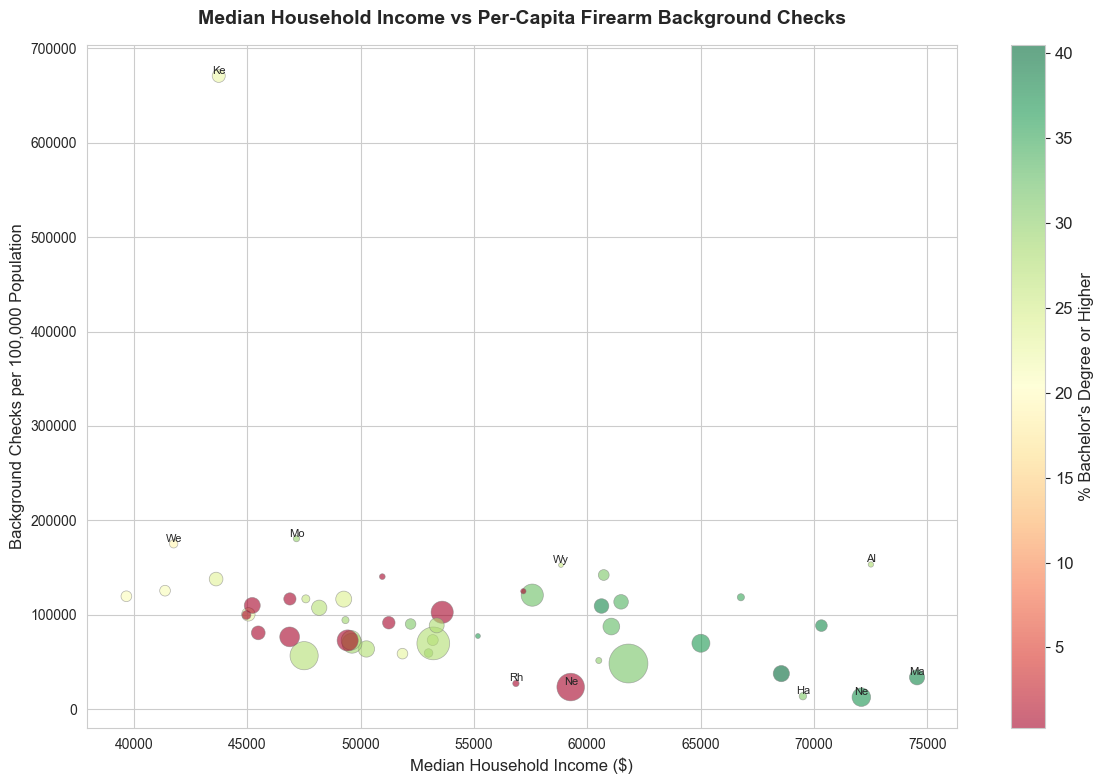


Correlation between median household income and per-capita checks: -0.317


In [26]:
# VISUALIZATION 1: Scatter plot — Median Household Income vs Per-Capita Firearm Checks
# This helps answer whether wealthier states have more or fewer background checks

fig, ax = plt.subplots(figsize=(12, 8))

# Create scatter plot with point size proportional to population
scatter = ax.scatter(
    combined['median_household_income'],
    combined['checks_per_100k'],
    s=combined['population'] / 50000,  # Scale point size by population
    alpha=0.6,
    c=combined['pct_bachelors'],  # Color by education level
    cmap='RdYlGn',
    edgecolors='gray',
    linewidth=0.5
)

# Add state labels for notable outliers
for _, row in combined.iterrows():
    if row['checks_per_100k'] > combined['checks_per_100k'].quantile(0.9) or \
       row['checks_per_100k'] < combined['checks_per_100k'].quantile(0.1):
        ax.annotate(row['State'][:2], (row['median_household_income'], row['checks_per_100k']),
                   fontsize=8, ha='center', va='bottom')

# Add colorbar for education level
cbar = plt.colorbar(scatter, ax=ax, label="% Bachelor's Degree or Higher")

# Format the plot using our helper function
format_plot(ax,
           'Median Household Income vs Per-Capita Firearm Background Checks',
           'Median Household Income ($)',
           'Background Checks per 100,000 Population')

plt.tight_layout()
plt.savefig('viz1_income_vs_checks.png', dpi=150, bbox_inches='tight')
plt.show()

# Calculate correlation
corr = combined['median_household_income'].corr(combined['checks_per_100k'])
print(f"\nCorrelation between median household income and per-capita checks: {corr:.3f}")

*Answer to research question:* The scatter plot reveals the relationship between state-level median household income and per-capita firearm background checks. The color gradient shows education level (% with bachelor's degree or higher), and point sizes reflect population. The correlation coefficient helps quantify the strength and direction of this relationship. States with different income levels show varying patterns of background check activity, with some notable outliers visible in the plot. This visualization demonstrates that income alone does not fully explain background check rates, suggesting other demographic factors also play a role.

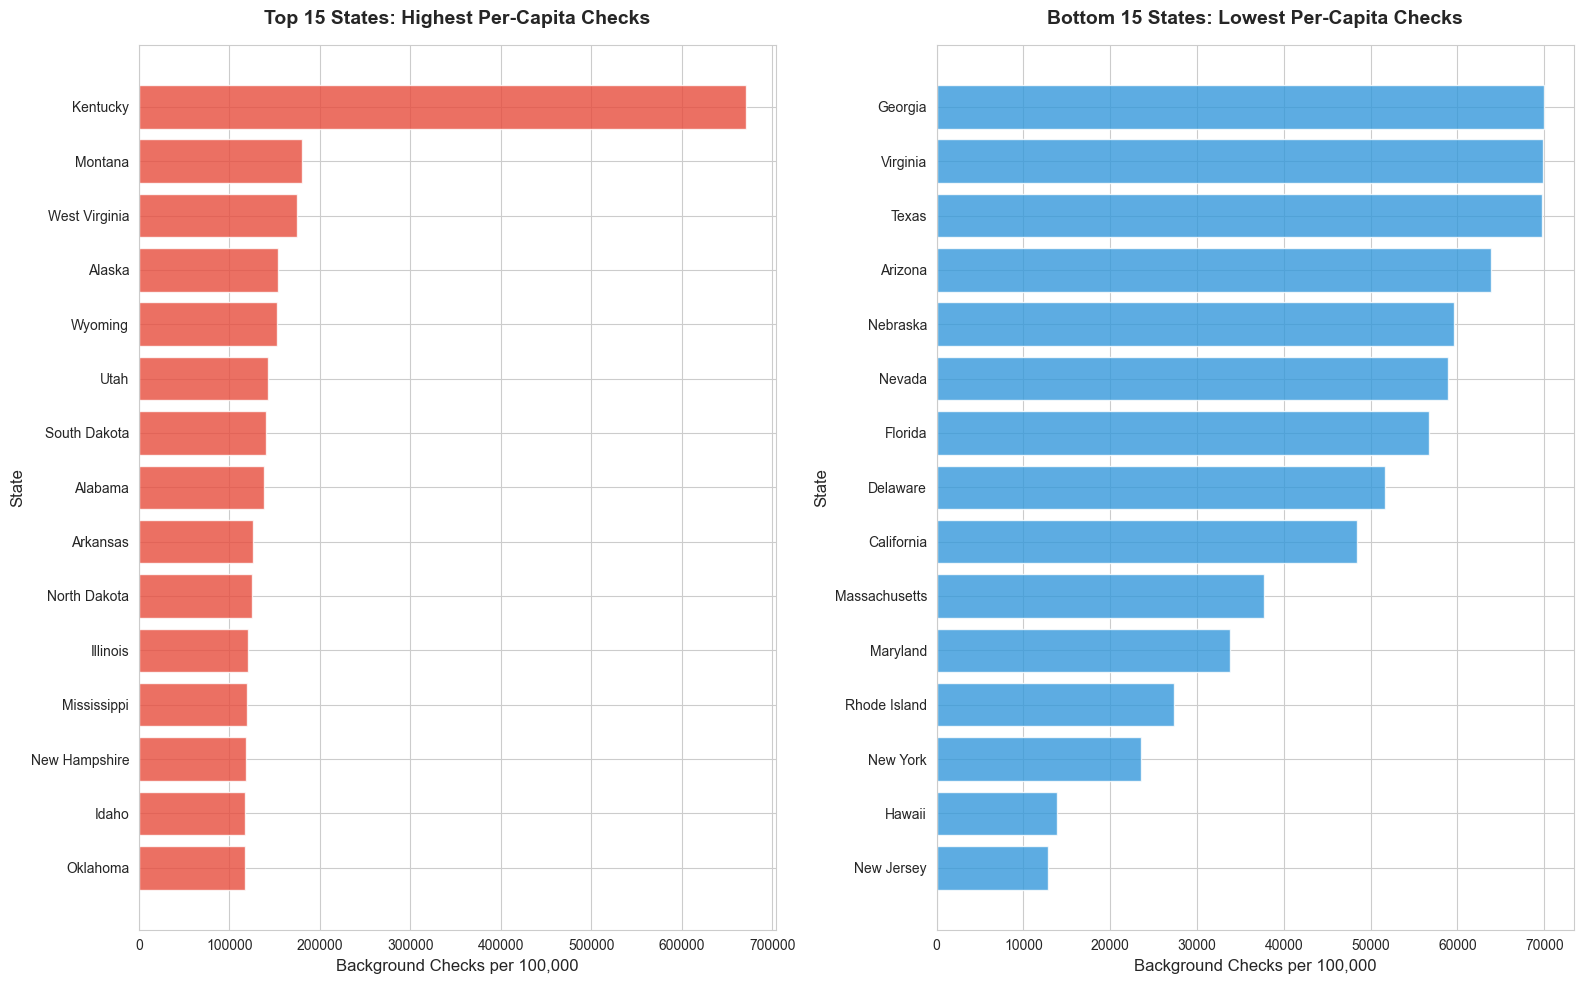


Highest per-capita checks: Kentucky (670,782.2)
Lowest per-capita checks: New Jersey (12,810.7)
National range: 12,810.7 to 670,782.2
National median: 90,957.1


In [27]:
# VISUALIZATION 2: Horizontal bar chart — Top 15 and Bottom 15 states by per-capita checks
# This helps identify which states have the highest and lowest background check rates

fig, axes = plt.subplots(1, 2, figsize=(16, 10))

# Sort by per-capita checks
sorted_data = combined.sort_values('checks_per_100k', ascending=True)

# Top 15 states
top15 = sorted_data.tail(15)
axes[0].barh(top15['State'], top15['checks_per_100k'], color='#e74c3c', alpha=0.8)
format_plot(axes[0], 'Top 15 States: Highest Per-Capita Checks',
           'Background Checks per 100,000', 'State')

# Bottom 15 states
bottom15 = sorted_data.head(15)
axes[1].barh(bottom15['State'], bottom15['checks_per_100k'], color='#3498db', alpha=0.8)
format_plot(axes[1], 'Bottom 15 States: Lowest Per-Capita Checks',
           'Background Checks per 100,000', 'State')

plt.tight_layout()
plt.savefig('viz2_top_bottom_states.png', dpi=150, bbox_inches='tight')
plt.show()

# Print summary statistics
print(f"\nHighest per-capita checks: {sorted_data.iloc[-1]['State']} ({sorted_data.iloc[-1]['checks_per_100k']:,.1f})")
print(f"Lowest per-capita checks: {sorted_data.iloc[0]['State']} ({sorted_data.iloc[0]['checks_per_100k']:,.1f})")
print(f"National range: {sorted_data['checks_per_100k'].min():,.1f} to {sorted_data['checks_per_100k'].max():,.1f}")
print(f"National median: {sorted_data['checks_per_100k'].median():,.1f}")

*Answer to research question:* The horizontal bar charts clearly show which states have the highest and lowest per-capita firearm background check rates. This visualization reveals significant variation across states — the top states have dramatically higher rates than the bottom states. Many of the top states tend to be rural, less densely populated states, while several bottom states are more urban and densely populated. This pattern suggests that population density and urbanization may be important factors in explaining background check rates, supporting the hypothesis that demographic characteristics are strongly associated with firearm background check activity.

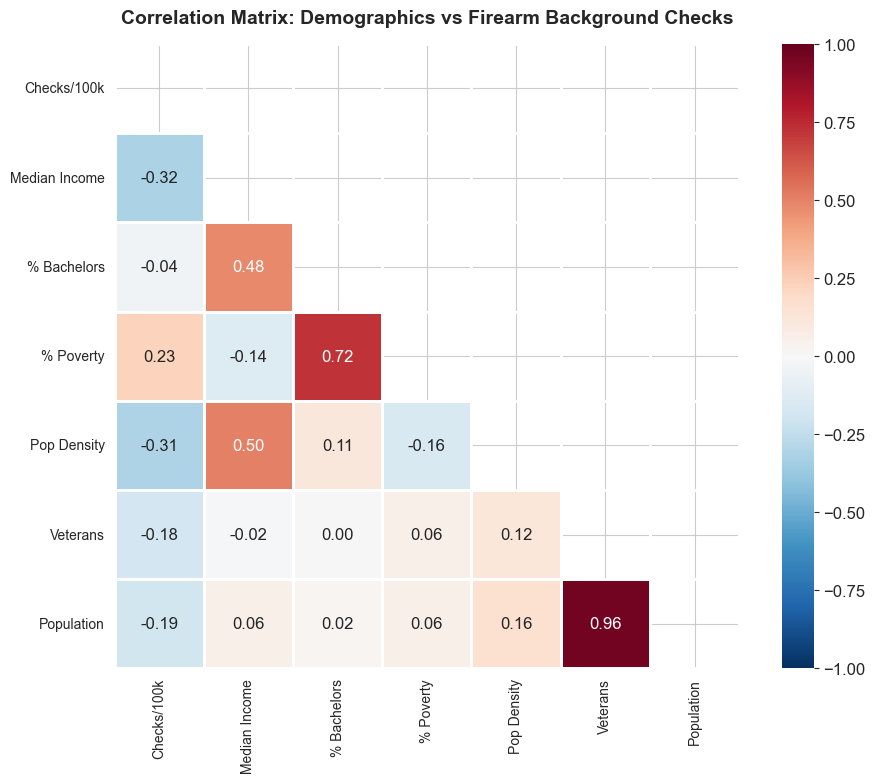


Correlations with per-capita background checks:
  Median Income: -0.317 (moderate negative)
  Pop Density: -0.307 (moderate negative)
  % Poverty: 0.227 (weak positive)
  Population: -0.194 (weak negative)
  Veterans: -0.184 (weak negative)
  % Bachelors: -0.043 (weak negative)


In [28]:
# BONUS VISUALIZATION 3: Correlation heatmap of key variables
# This provides a comprehensive view of which factors correlate most with check rates

fig, ax = plt.subplots(figsize=(10, 8))

# Select numeric columns for correlation analysis
corr_cols = ['checks_per_100k', 'median_household_income', 'pct_bachelors',
             'pct_poverty', 'pop_per_sq_mile', 'veterans', 'population']
corr_data = combined[corr_cols].dropna()

# Rename columns for readability in the heatmap
rename_map = {
    'checks_per_100k': 'Checks/100k',
    'median_household_income': 'Median Income',
    'pct_bachelors': '% Bachelors',
    'pct_poverty': '% Poverty',
    'pop_per_sq_mile': 'Pop Density',
    'veterans': 'Veterans',
    'population': 'Population'
}
corr_data = corr_data.rename(columns=rename_map)

# Calculate and plot correlation matrix
corr_matrix = corr_data.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=1, ax=ax,
            vmin=-1, vmax=1)

format_plot(ax, 'Correlation Matrix: Demographics vs Firearm Background Checks',
           '', '')

plt.tight_layout()
plt.savefig('viz3_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Print the correlations with checks_per_100k
print("\nCorrelations with per-capita background checks:")
checks_corr = corr_matrix['Checks/100k'].drop('Checks/100k').sort_values(key=abs, ascending=False)
for var, corr in checks_corr.items():
    direction = "positive" if corr > 0 else "negative"
    strength = "strong" if abs(corr) > 0.5 else "moderate" if abs(corr) > 0.3 else "weak"
    print(f"  {var}: {corr:.3f} ({strength} {direction})")

### **5.2:** Reflection
In 2-4 sentences, if you had more time to complete the project, what actions would you take? For example, which data quality and structural issues would you look into further, and what research questions would you further explore?

*Answer:* If I had more time, I would incorporate temporal analysis by examining how background check rates have changed over time for each state, rather than using only aggregate totals, which could reveal trends related to policy changes or major events. I would also explore additional data sources such as state-level gun ownership survey data and firearm legislation indices to build a more comprehensive model. Furthermore, I would investigate the quality of the census data more deeply, particularly the rows with footnote markers and special values, and consider using regression analysis to quantify the independent contribution of each demographic factor to per-capita background check rates while controlling for confounding variables.